In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 02b — Round 3 preprocessing (writes to `data_r3/`, keeps `data/` unchanged)

Same steps as 02, but reads `data/regions_r3.csv` (42 regions, 8 validation regions) and writes everything to a **new folder `data_r3/`**. The old `data/patches`, `data/patch_index.csv` and `data/norm_stats.json` used by 04a/b/c stay as they are.

**Input:** `data/raw/*_s1_2021.tif`, `data/raw/*_label.tif`, `data/regions.csv` (from notebook 01)

**Output:**
* `data/patches/train|val|test/*.npz` — each file holds `x` (12 months × 3 bands × 256 × 256, clipped dB, float16, NaN = no data) and `y` (256 × 256 class ids, 255 = ignore)
* `data/norm_stats.json` — band means/stds (from **training regions only**), clip ranges, classes, class weights
* `data/class_distribution.csv` and figures for the report

**Steps:** understand the data → (calibration / dB / terrain correction: already done) → speckle → clip → label remap → patching → splits → normalisation statistics → class distribution and weights → final checks.

In [1]:
import sys, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm

sys.path.append(".")
from preprocess import (CLASSES, COLORS, IGNORE, BANDS, CLIP, decode_s1, clip_db,
                        remap_worldcover, normalise)

YEAR    = 2021
DATA    = Path("data_r3")                  # round-3 output folder
RAW     = Path("data") / "raw"             # shared raw downloads (read only)
DATA.mkdir(exist_ok=True)
PATCHES = DATA / "patches"
PATCH   = 256
SPECKLE_FILTER = False      # extra 3x3 median filter; keep False for the baseline (test it later as a model variant)
random.seed(42); np.random.seed(42)

regions = pd.read_csv(Path("data") / "regions_r3.csv")
cmap = ListedColormap(COLORS)
print(regions.groupby("split").name.apply(list).to_string())

split
test     [cairo, okavango, black_forest, mekong_delta, ...
train    [paris, delhi, sao_paulo, lagos, rhine_neckar,...
val      [madrid, las_vegas, danube_delta, iowa, saskat...


## 1. Understand the data first

**What the numbers mean** (all in dB):

* **VV** — strong for rough surfaces and buildings (double bounce). Water ≈ −20 dB or lower, cities ≈ 0 dB.
* **VH** — strong for vegetation (volume scattering). Typically 6–10 dB lower than VV.
* **VV−VH** — the ratio. Higher for bare/smooth surfaces, lower for dense vegetation.

The histograms below show the value range per class — this is literally what the model has to learn from.

In [2]:
def load_region(name):
    with rasterio.open(RAW / f"{name}_s1_{YEAR}.tif") as f:
        raw = f.read()                                   # (36, H, W) int16
    with rasterio.open(RAW / f"{name}_label.tif") as f:
        wc = f.read(1)                                   # WorldCover codes
    x = decode_s1(raw.reshape(12, 3, *raw.shape[1:]))    # (12, 3, H, W) dB, NaN = no data
    return x, remap_worldcover(wc)                       # y: 0..6, 255 = ignore

x, y = load_region("rhine_neckar")
print("x shape (month, band, H, W):", x.shape, "| y shape:", y.shape)
print("no-data share per month (%):", np.round(np.isnan(x[:, 0]).mean((1, 2)) * 100, 1))
for b, name in enumerate(BANDS):
    v = x[:, b]
    print(f"{name:6s} min {np.nanmin(v):7.1f}  1% {np.nanpercentile(v, 1):6.1f}  "
          f"median {np.nanmedian(v):6.1f}  99% {np.nanpercentile(v, 99):6.1f}  max {np.nanmax(v):6.1f}")

x shape (month, band, H, W): (12, 3, 1200, 1200) | y shape: (1200, 1200)
no-data share per month (%): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
VV     min   -26.1  1%  -19.7  median   -8.7  99%    5.3  max   31.3
VH     min   -30.8  1%  -25.5  median  -15.9  99%   -4.4  max   25.4
VV_VH  min   -18.1  1%    2.2  median    7.0  99%   17.8  max   46.0


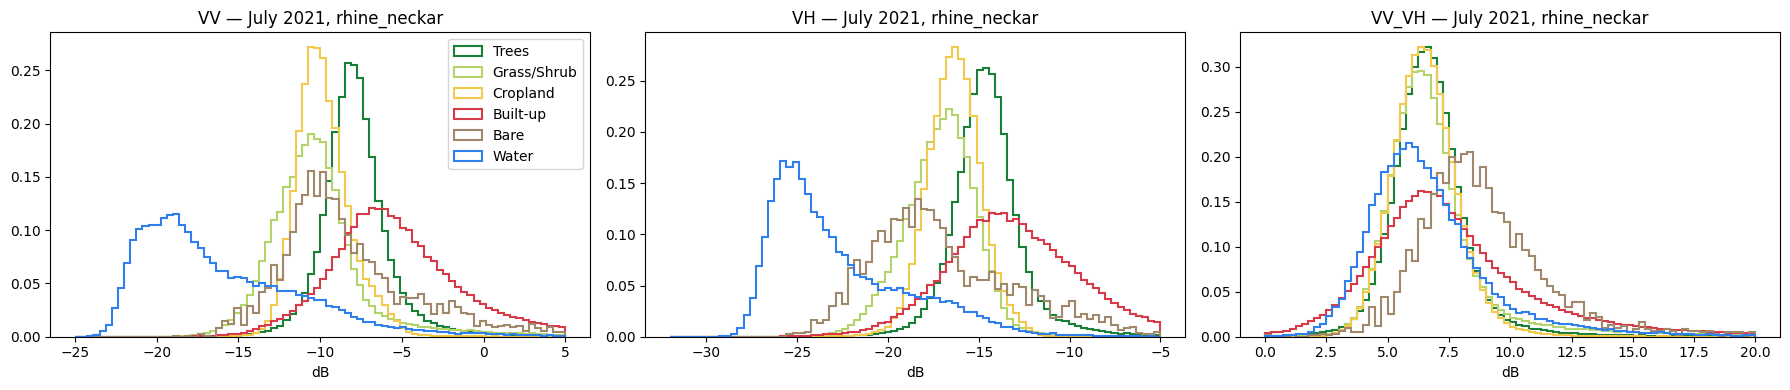

In [3]:
# Value distribution per class (July) — which classes overlap = which ones the model will confuse
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for b, (ax, name) in enumerate(zip(axes, BANDS)):
    for c, cname in enumerate(CLASSES):
        v = x[6, b][(y == c) & ~np.isnan(x[6, b])]
        if v.size > 500:
            ax.hist(v, bins=80, range=CLIP[name], density=True, histtype="step",
                    lw=1.5, color=COLORS[c], label=cname)
    ax.set_title(f"{name} — July {YEAR}, rhine_neckar"); ax.set_xlabel("dB")
axes[0].legend(); plt.tight_layout(); plt.show()

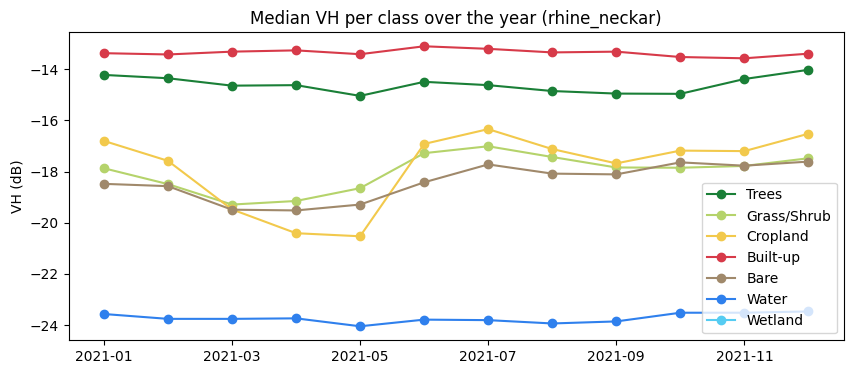

In [4]:
# How each class changes over the year (median VH per month) — the seasonal effect
med = pd.DataFrame({cname: [np.nanmedian(x[m, 1][y == c]) if (y == c).sum() > 500 else np.nan
                            for m in range(12)] for c, cname in enumerate(CLASSES)},
                   index=[f"{YEAR}-{m + 1:02d}" for m in range(12)])
ax = med.plot(figsize=(10, 4), color=[COLORS[CLASSES.index(c)] for c in med.columns], marker="o",
              title="Median VH per class over the year (rhine_neckar)")
ax.set_ylabel("VH (dB)"); plt.show()

**What you should see:** water lowest, built-up highest in VV; cropland VH rising strongly in spring/summer and dropping after harvest.
That seasonal swing is why every month is paired with the same label during training.

## 2. Calibration, dB conversion, terrain correction — already done

Earth Engine's `COPERNICUS/S1_GRD` was processed with ESA SNAP: orbit file applied, GRD border and thermal noise removal,
**radiometric calibration** to σ⁰, **terrain correction** (SRTM / ASTER DEM) and **conversion to dB**.
Notebook 01 additionally masked edge noise (VV < −30 dB) and built **monthly composites by averaging in linear power**.

## 3. Speckle reduction

The main speckle reduction is the **temporal average** (all images in a month, see `images_per_month` in `regions.csv`).
An optional 3 × 3 median filter can be switched on with `SPECKLE_FILTER = True` (compare it later as a model variant).

In [5]:
def speckle_filter(x):
    from scipy.ndimage import median_filter            # pip install scipy (only needed if used)
    out = x.copy()
    for m in range(x.shape[0]):
        for b in range(2):                             # VV, VH; ratio is recomputed
            band = np.where(np.isnan(x[m, b]), np.nanmedian(x[m, b]), x[m, b])
            out[m, b] = np.where(np.isnan(x[m, b]), np.nan, median_filter(band, size=3))
        out[m, 2] = out[m, 0] - out[m, 1]
    return out

imgs = regions.images_per_month.str.split().apply(lambda v: list(map(int, v)))
print("Images per monthly composite: median", int(np.median(np.concatenate(imgs.values))),
      "| min", int(np.min(np.concatenate(imgs.values))))

Images per monthly composite: median 5 | min 1


## 4. Clip, remap labels, cut patches, split by region

* **Clip** each band to a sensible range (VV −25…5, VH −32…−5, ratio 0…20 dB) so rare extreme pixels don't dominate.
* **Label remap**: WorldCover's 11 classes → our 7 (snow/no data → 255 = ignore). Pixels with no radar in a month become ignore for that month (done when loading).
* **Patches**: 256 × 256 pixels (2.56 km). Training regions use a stride of 236 so the whole 1200-pixel region is used (5 × 5 = 25 patches, slight overlap); val/test use non-overlapping patches (4 × 4 = 16) so no pixel is counted twice in the metrics.
* Patches with more than 50 % ignore pixels are skipped.
* **Splits are by region** (from `regions.csv`), never by random patch — neighbouring patches look almost identical, so a random split would leak test information into training.

In [6]:
def positions(size, stride, patch=PATCH):
    p = list(range(0, size - patch + 1, stride))
    if p[-1] != size - patch and stride < patch:      # make sure the last row/column is covered
        p.append(size - patch)
    return p

import shutil
if PATCHES.exists():
    shutil.rmtree(PATCHES)          # start clean: removes old/unzipped patches, avoids leftovers
for s in ["train", "val", "test"]:
    (PATCHES / s).mkdir(parents=True, exist_ok=True)

index = []
for r in tqdm(list(regions.itertuples()), desc="regions"):
    x, y = load_region(r.name)
    if SPECKLE_FILTER:
        x = speckle_filter(x)
    x = clip_db(x)
    stride = 236 if r.split == "train" else PATCH
    H, W = y.shape
    for i in positions(H, stride):
        for j in positions(W, stride):
            yp = y[i:i + PATCH, j:j + PATCH]
            if (yp == IGNORE).mean() > 0.5:
                continue
            xp = x[:, :, i:i + PATCH, j:j + PATCH].astype(np.float16)
            fname = PATCHES / r.split / f"{r.name}_{i:04d}_{j:04d}.npz"
            np.savez_compressed(fname, x=xp, y=yp)
            counts = np.bincount(yp[yp != IGNORE], minlength=len(CLASSES))
            index.append({"file": fname.relative_to(DATA).as_posix(), "region": r.name, "split": r.split,
                          "row": i, "col": j, **dict(zip(CLASSES, counts)),
                          "nodata_%": float(np.isnan(xp[:, 0]).mean() * 100)})
index = pd.DataFrame(index)
index.to_csv(DATA / "patch_index.csv", index=False)
print(index.groupby("split").size().rename("patches").to_string())

regions:   0%|          | 0/42 [00:00<?, ?it/s]

split
test      96
train    700
val      128


## 5. Normalisation statistics — training regions only

Normalisation rescales each band to mean ≈ 0, std ≈ 1 so the network trains stably.
The mean and std are computed **only from training patches** (all months, valid pixels). Using validation or test data here would be *data leakage*.
The same numbers are used later for val/test and in the prototype.

In [7]:
n = np.zeros(3); s = np.zeros(3); ss = np.zeros(3)
for f in tqdm(index[index.split == "train"].file, desc="stats"):
    xp = np.load(DATA / f)["x"].astype(np.float64)                 # (12, 3, 256, 256)
    for b in range(3):
        v = xp[:, b][~np.isnan(xp[:, b])]
        n[b] += v.size; s[b] += v.sum(); ss[b] += (v ** 2).sum()
mean = s / n
std = np.sqrt(ss / n - mean ** 2)
for b, name in enumerate(BANDS):
    print(f"{name:6s} mean {mean[b]:7.2f} dB   std {std[b]:5.2f} dB")

stats:   0%|          | 0/700 [00:00<?, ?it/s]

VV     mean  -10.77 dB   std  5.44 dB
VH     mean  -18.54 dB   std  5.83 dB
VV_VH  mean    7.73 dB   std  2.91 dB


## 6. Class distribution and class weights

Required in the report. Pixels are counted once per patch (the same label is used for all 12 months).
Class weights `1 / sqrt(frequency)` (normalised to mean 1) are saved for the loss function, so rare classes are not ignored.

Pixels per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
split,,,,,,,
train,5441179,6279781,9690447,11035609,4261511,4945761,4220912
val,930014,1891093,835340,2583199,133015,273214,1742733
test,1341659,1017776,711627,1379209,1087194,252109,501882


Share per class (%)


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
split,,,,,,,
train,11.86,13.69,21.12,24.06,9.29,10.78,9.20
val,11.09,22.54,9.96,30.79,1.59,3.26,20.77
test,21.33,16.18,11.31,21.92,17.28,4.01,7.98


Class weights: {'Trees': np.float64(1.05), 'Grass/Shrub': np.float64(0.97), 'Cropland': np.float64(0.78), 'Built-up': np.float64(0.73), 'Bare': np.float64(1.18), 'Water': np.float64(1.1), 'Wetland': np.float64(1.19)}


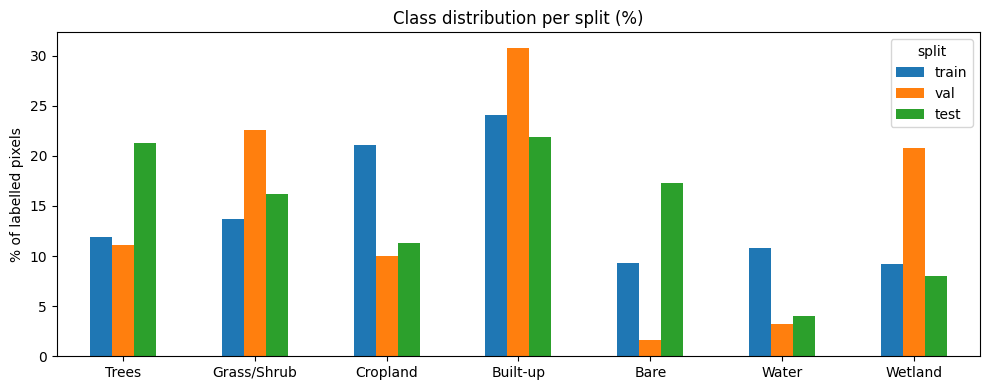

In [8]:
dist = index.groupby("split")[CLASSES].sum().loc[["train", "val", "test"]]
dist_pct = (100 * dist.div(dist.sum(axis=1), axis=0)).round(2)
dist.to_csv(DATA / "class_distribution_pixels.csv"); dist_pct.to_csv(DATA / "class_distribution.csv")
print("Pixels per class"); display(dist)
print("Share per class (%)"); display(dist_pct)

freq = dist.loc["train"].values / dist.loc["train"].values.sum()
weights = 1 / np.sqrt(np.maximum(freq, 1e-6)); weights = weights / weights.mean()
print("Class weights:", dict(zip(CLASSES, np.round(weights, 2))))

ax = dist_pct.T.plot.bar(figsize=(10, 4), rot=0, title="Class distribution per split (%)")
ax.set_ylabel("% of labelled pixels"); plt.tight_layout()
plt.savefig(DATA / "class_distribution.png", dpi=150); plt.show()

In [9]:
stats = {
    "bands": BANDS, "units": "dB, clipped", "clip": CLIP,
    "mean": mean.round(4).tolist(), "std": std.round(4).tolist(),
    "classes": CLASSES, "ignore_index": IGNORE,
    "class_weights": np.round(weights, 4).tolist(),
    "year": YEAR, "patch_size": PATCH, "speckle_filter": SPECKLE_FILTER,
    "train_regions": sorted(regions[regions.split == "train"].name),
    "val_regions":   sorted(regions[regions.split == "val"].name),
    "test_regions":  sorted(regions[regions.split == "test"].name),
}
with open(DATA / "norm_stats.json", "w") as f:
    json.dump(stats, f, indent=2)
print(json.dumps(stats, indent=2)[:600], "...")

{
  "bands": [
    "VV",
    "VH",
    "VV_VH"
  ],
  "units": "dB, clipped",
  "clip": {
    "VV": [
      -25.0,
      5.0
    ],
    "VH": [
      -32.0,
      -5.0
    ],
    "VV_VH": [
      0.0,
      20.0
    ]
  },
  "mean": [
    -10.7679,
    -18.5369,
    7.7339
  ],
  "std": [
    5.4385,
    5.8257,
    2.9067
  ],
  "classes": [
    "Trees",
    "Grass/Shrub",
    "Cropland",
    "Built-up",
    "Bare",
    "Water",
    "Wetland"
  ],
  "ignore_index": 255,
  "class_weights": [
    1.0453,
    0.973,
    0.7833,
    0.734,
    1.1812,
    1.0964,
    1.1868
  ],
  "year": 2021,
  ...


## 7. Final checks before training

1. No region appears in two splits.
2. Normalised training data has mean ≈ 0 and std ≈ 1.
3. Every class appears in every split.
4. Random patches look right: bright built-up in VV, dark water, label lines up.

1. Splits are disjoint by region ✔
2. normalised mean per band: [0.16 0.09 0.11] | std: [0.8  0.88 0.98]
3. Missing classes: none ✔


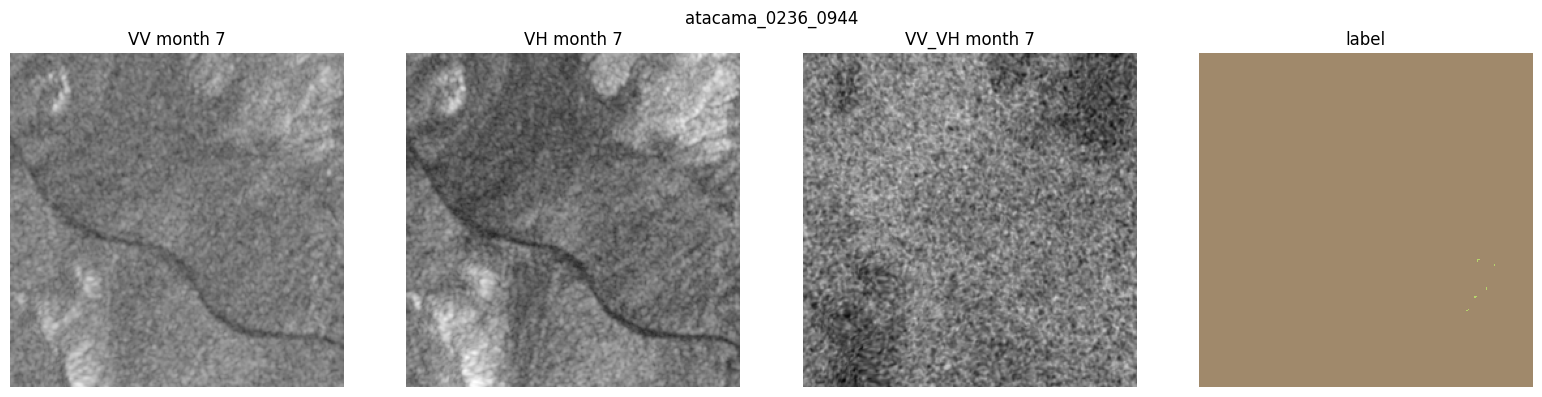

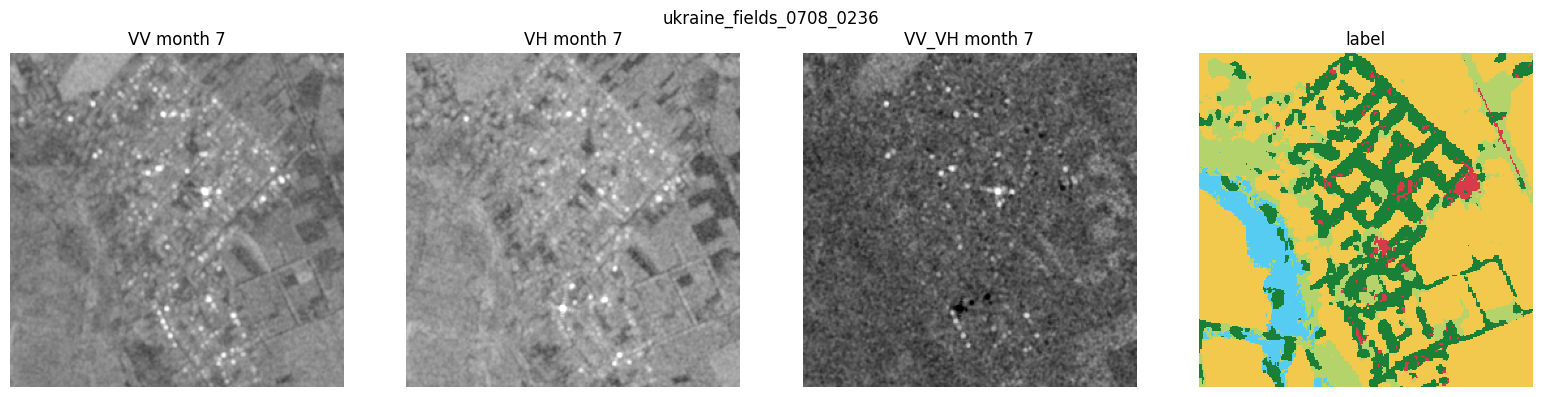

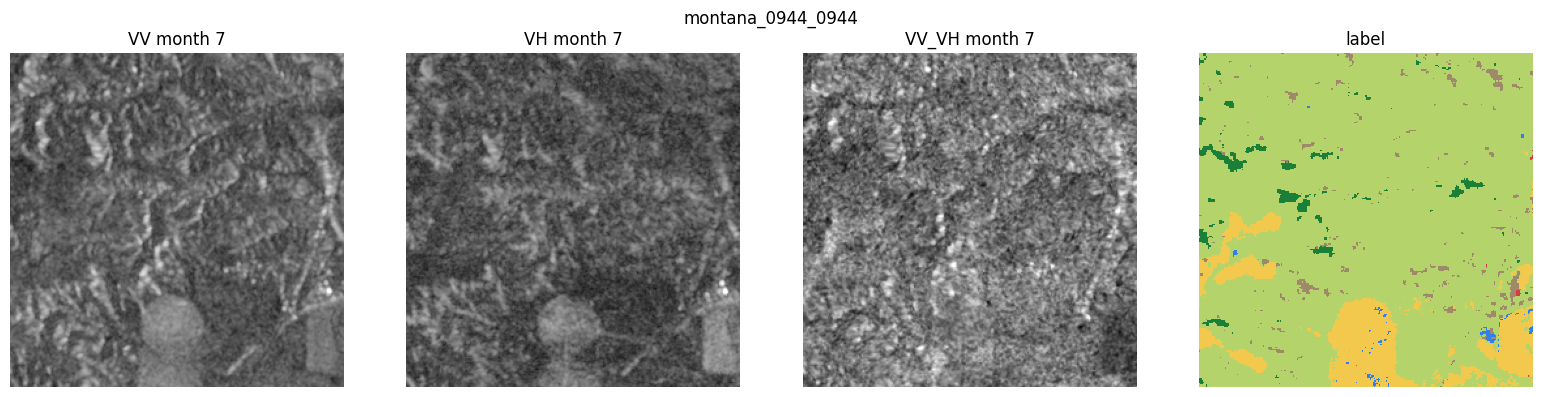

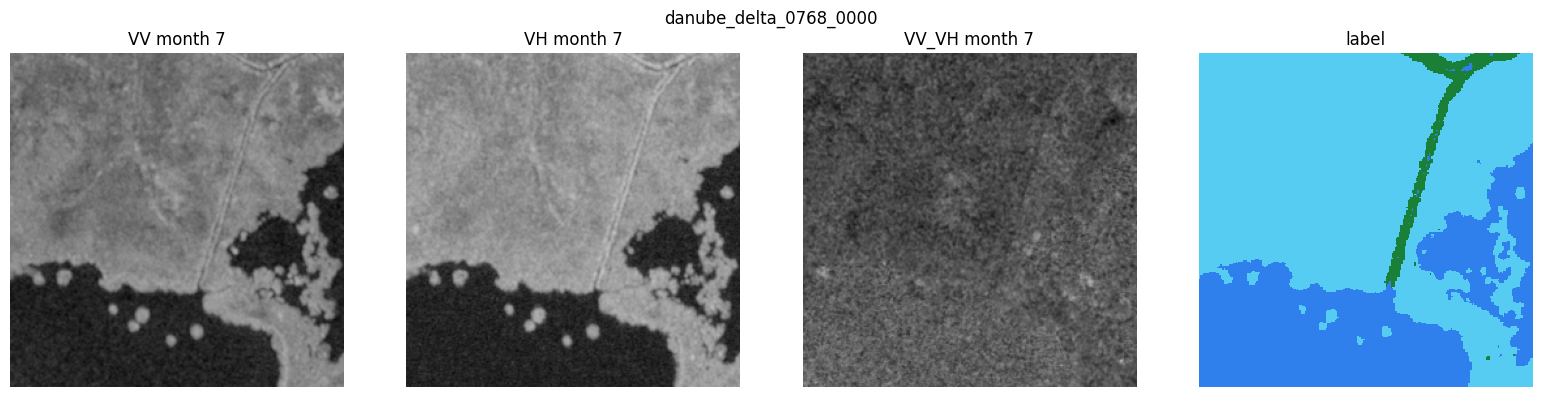

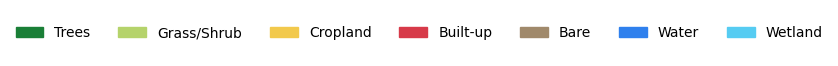

In [10]:
# 1. no region in two splits
sets = {s: set(index[index.split == s].region) for s in ["train", "val", "test"]}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("1. Splits are disjoint by region ✔")

# 2. normalisation check on 30 random training patches
sample = [np.load(DATA / f)["x"].astype(np.float32) for f in index[index.split == "train"].file.sample(30, random_state=0)]
z = np.stack([normalise(xp, stats) for xp in sample])           # (30, 12, 3, 256, 256)
print("2. normalised mean per band:", np.round(z.mean((0, 1, 3, 4)), 2), "| std:", np.round(z.std((0, 1, 3, 4)), 2))

# 3. every class in every split
missing = [(s, c) for s in dist.index for c in CLASSES if dist.loc[s, c] == 0]
print("3. Missing classes:", missing if missing else "none ✔")

# 4. visual check
def show_patch(f, month=6):
    d = np.load(DATA / f); xp, yp = d["x"].astype(np.float32), d["y"]
    fig, ax = plt.subplots(1, 4, figsize=(16, 4))
    for b, (a, name) in enumerate(zip(ax, BANDS)):
        a.imshow(xp[month, b], cmap="gray", vmin=CLIP[name][0], vmax=CLIP[name][1]); a.set_title(f"{name} month {month + 1}")
    ax[3].imshow(np.ma.masked_equal(yp, IGNORE), cmap=cmap, vmin=0, vmax=6, interpolation="nearest")
    ax[3].set_title("label")
    for a in ax: a.axis("off")
    fig.suptitle(Path(f).stem); plt.tight_layout(); plt.show()

for f in index.sample(4, random_state=1).file:
    show_patch(f)

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS]
plt.figure(figsize=(10, 0.6)); plt.legend(handles, CLASSES, ncol=7, loc="center", frameon=False); plt.axis("off"); plt.show()

In [11]:
total_mb = sum((DATA / f).stat().st_size for f in index.file) / 1e6
print(f"Patches: {len(index)}  |  size on disk: {total_mb / 1e3:.2f} GB")
print("Training samples per epoch (one random month per patch):", (index.split == 'train').sum())
print("Val/test samples (all 12 months):", 12 * (index.split != 'train').sum())

Patches: 924  |  size on disk: 3.23 GB
Training samples per epoch (one random month per patch): 700
Val/test samples (all 12 months): 2688


✅ **Ready for training.** Continue with **03_training.ipynb**. Keep `preprocess.py` next to the training notebook and the prototype so the same clipping and normalisation are used everywhere.

**For the report, save from this notebook:** the class-distribution table and figure, the per-class histogram, the seasonal VH plot, normalisation statistics, and the number of patches per split.